# Project 2, Step 5: Dollar impact of a better forecast

**Question:** how many inventory dollars does the 4-week moving average forecast free up compared with a naive forecast, and do those savings hold up on demand the model never saw?

This is the link between Project 1 and Project 2. Project 1 showed the moving average is more accurate. Here that accuracy is turned into dollars, two ways:
1. **Planned saving:** what the safety stock formula (and the Excel workbook) says.
2. **Realized saving:** what happens when both policies are replayed on the 13-week holdout, compared at the **same achieved service level**.

**Policy** (periodic review, as in the updated workbook):
- $SS = z \cdot \sigma_1 \sqrt{R + L}$, $ROP = F \cdot (R + L) + SS$
- $\sigma_1$ = 1-week forecast RMSE, $R$ = review period (1 week), $L$ = lead time (1 week), $F$ = weekly demand forecast, $z$ = safety factor

Order quantity $Q$, costs, and assumptions are identical for both forecasts. Only the forecast changes.

In [1]:
import sys
from pathlib import Path
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_DIR / "src"))
from inventory_sim import cycle_counts, simulate

STORE_ID = "CA_1"
DATA_DIR = PROJECT_DIR / "data"
P1_DIR = PROJECT_DIR.parent / "project-1-forecast-fva" / "data" / "processed"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"

# Base case, same as the Excel Assumptions sheet
LEAD_TIME, REVIEW = 1, 1
PROTECT = REVIEW + LEAD_TIME
CSL_TARGET, UNIT_COST_PCT, HOLD_RATE, ORDER_COST, MAX_WEEKS = 0.95, 0.70, 0.25, 5.0, 4
MA_WINDOW = 4
z = NormalDist().inv_cdf(CSL_TARGET)

inputs = pd.read_csv(DATA_DIR / f"sku_policy_inputs_{STORE_ID}.csv")
holdout = pd.read_csv(DATA_DIR / f"holdout_demand_{STORE_ID}.csv")
demand = (holdout.pivot(index="item_id", columns="wm_yr_wk", values="units")
          .loc[inputs["item_id"]].to_numpy(float))
n_weeks = demand.shape[1]

d = inputs["avg_weekly_demand"].to_numpy()
C = UNIT_COST_PCT * inputs["last_train_price"].to_numpy()
H = HOLD_RATE * C
with np.errstate(divide="ignore", invalid="ignore"):
    eoq = np.where(d > 0, np.sqrt(2 * 52 * d * ORDER_COST / H), 0.0)
Q = np.where(eoq > 0, np.minimum(eoq, MAX_WEEKS * d), 0.0)
Q_units = np.where(Q > 0, np.maximum(1, np.ceil(Q)), 0)

METHODS = ["Naive", "Moving avg"]
sigma = {"Naive": inputs["rmse_naive"].to_numpy(), "Moving avg": inputs["rmse_ma"].to_numpy()}
active = d > 0     # 9 SKUs had no calibration sales and get no policy (as in Step 4)
sku_type = np.where(inputs["slow_mover_flag"], "Slow mover", "Regular")
cat = inputs["cat_id"].to_numpy()

## 1. Planned saving: safety stock dollars from the formula

- $SS\,\$ = SS \times C$: value of the buffer at unit cost (inventory dollars tied up)
- Annual holding cost of the buffer $= h \times SS\,\$$, with $h$ = 25% per year

Totals match the updated workbook Summary sheet (all 2,717 SKUs).

In [2]:
df = pd.DataFrame({"cat_id": cat, "type": sku_type})
for m in METHODS:
    df[f"SS $ {m}"] = z * sigma[m] * np.sqrt(PROTECT) * C

def dollar_table(by):
    t = df.groupby(by)[["SS $ Naive", "SS $ Moving avg"]].sum()
    t.loc["Total"] = t.sum()
    t["Freed up $"] = t["SS $ Naive"] - t["SS $ Moving avg"]
    t["Freed up %"] = t["Freed up $"] / t["SS $ Naive"]
    t["Holding cost saved $/yr"] = HOLD_RATE * t["Freed up $"]
    return t

money = {c: "${:,.0f}" for c in ["SS $ Naive", "SS $ Moving avg", "Freed up $", "Holding cost saved $/yr"]}
money["Freed up %"] = "{:.1%}"
planned_cat = dollar_table("cat_id")
display(planned_cat.style.format(money))
display(dollar_table("type").style.format(money))

,SS $ Naive,SS $ Moving avg,Freed up $,Freed up %,Holding cost saved $/yr
cat_id,,,,,
FOODS,"$43,930","$42,055","$1,875",4.3%,$469
HOBBIES,"$14,332","$11,804","$2,528",17.6%,$632
HOUSEHOLD,"$26,384","$22,421","$3,963",15.0%,$991
Total,"$84,646","$76,281","$8,365",9.9%,"$2,091"


,SS $ Naive,SS $ Moving avg,Freed up $,Freed up %,Holding cost saved $/yr
type,,,,,
Regular,"$78,380","$69,818","$8,562",10.9%,"$2,140"
Slow mover,"$6,266","$6,463",$-197,-3.1%,$-49
Total,"$84,646","$76,281","$8,365",9.9%,"$2,091"


## 2. Replay on the holdout with a weekly-updated forecast

In Step 4 the forecast $F$ was held fixed at the training average for the whole quarter. A store does not run like that: each week it re-forecasts. So here $F$ is updated every week from actual sales the store has already seen:
- Naive: $F_t = A_{t-1}$
- Moving average: $F_t = \frac{1}{4}(A_{t-1} + A_{t-2} + A_{t-3} + A_{t-4})$

The reorder point then moves each week: $ROP_t = F_t (R + L) + SS$. This is also how $\sigma_1$ was measured in notebook 01, so the buffer and the forecast now match.

The first holdout weeks need the last 4 training weeks, read from Project 1's processed data.

In [3]:
weekly = pd.read_parquet(P1_DIR / f"weekly_sku_{STORE_ID}.parquet")
wide = (weekly[weekly["item_id"].isin(inputs["item_id"])]
        .pivot(index="item_id", columns="wm_yr_wk", values="units").loc[inputs["item_id"]])
first = list(wide.columns).index(holdout["wm_yr_wk"].min())
hist = wide.iloc[:, first - MA_WINDOW: first + n_weeks].to_numpy(float)   # 4 training weeks + holdout
assert np.array_equal(hist[:, MA_WINDOW:], demand), "holdout weeks do not line up"

forecast = {
    "Naive": hist[:, MA_WINDOW - 1: MA_WINDOW - 1 + n_weeks],
    "Moving avg": np.stack([hist[:, t:t + MA_WINDOW].mean(axis=1) for t in range(n_weeks)], axis=1),
}

def replay(method, csl_target, weekly_forecast=True):
    ss = NormalDist().inv_cdf(csl_target) * sigma[method] * np.sqrt(PROTECT)
    F = forecast[method] if weekly_forecast else np.repeat(d[:, None], n_weeks, axis=1)
    out = simulate(F * PROTECT + ss[:, None], Q_units, np.round(ss + Q_units / 2), demand, LEAD_TIME)
    n_cyc, n_bad = cycle_counts(out["lost"], out["received"])
    return pd.DataFrame({"cat_id": cat, "type": sku_type, "cycles": n_cyc, "bad": n_bad,
                         "demand": demand.sum(axis=1), "lost": out["lost"].sum(axis=1),
                         "inv_$": out["inv_avg"].mean(axis=1) * C})[active]

def service(r, by=None):
    g = r.groupby(by) if by else r.assign(_="All").groupby("_")
    t = g[["cycles", "bad", "demand", "lost", "inv_$"]].sum()
    return pd.DataFrame({"CSL": 1 - t["bad"] / t["cycles"], "Fill rate": 1 - t["lost"] / t["demand"],
                         "Avg inventory $": t["inv_$"]})

fs = {"CSL": "{:.1%}", "Fill rate": "{:.1%}", "Avg inventory $": "${:,.0f}"}
same_target = pd.concat({
    (m, "fixed (Step 4)"): service(replay(m, CSL_TARGET, weekly_forecast=False)) for m in METHODS
} | {
    (m, "updated weekly"): service(replay(m, CSL_TARGET)) for m in METHODS
}).droplevel(2)
same_target.index.names = ["Forecast", "Forecast F"]
same_target.sort_index().style.format(fs)

At the same 95% target the two policies land at **different** achieved service levels, so comparing their inventory directly is not fair. One is buying extra service with extra stock.

## 3. Realized saving: compare at the same achieved service level

Run each policy across a range of targets (60% to 99.5%), record achieved CSL and average inventory, and read off the inventory each one needs to actually achieve 95% (linear interpolation between runs). This gives each forecast's service vs inventory curve. The lower curve is the better forecast.

In [4]:
TARGETS = [0.60, 0.70, 0.80, 0.85, 0.90, 0.925, 0.95, 0.97, 0.98, 0.99, 0.995]
curve = []
for m in METHODS:
    for tgt in TARGETS:
        r = replay(m, tgt)
        groups = [("All", r), ("Regular", r[r["type"] == "Regular"])] + list(r.groupby("cat_id"))
        for g, sub in groups:
            s = service(sub).iloc[0]
            curve.append({"method": m, "target": tgt, "group": g, **s.to_dict()})
curve = pd.DataFrame(curve)

def inv_at(method, group, csl=0.95):
    c = curve[(curve["method"] == method) & (curve["group"] == group)].sort_values("CSL")
    assert c["CSL"].is_monotonic_increasing and c["CSL"].min() < csl < c["CSL"].max()
    return np.interp(csl, c["CSL"], c["Avg inventory $"])

realized = pd.DataFrame({m: {g: inv_at(m, g) for g in ["All", "Regular", "FOODS", "HOBBIES", "HOUSEHOLD"]}
                         for m in METHODS})
realized["Saved $"] = realized["Naive"] - realized["Moving avg"]
realized["Saved % of inventory"] = realized["Saved $"] / realized["Naive"]
realized.columns = ["Avg inv $ at 95% CSL, naive", "Avg inv $ at 95% CSL, moving avg",
                    "Saved $", "Saved % of inventory"]
display(realized.style.format({c: "${:,.0f}" for c in realized.columns[:3]} | {"Saved % of inventory": "{:+.1%}"}))

# Same read-off for the whole store at other achieved service levels
by_level = pd.DataFrame({f"{lvl:.0%}": {m: inv_at(m, "All", lvl) for m in METHODS} for lvl in [0.85, 0.90, 0.95, 0.97]}).T
by_level["Saved $"] = by_level["Naive"] - by_level["Moving avg"]
by_level["Saved %"] = by_level["Saved $"] / by_level["Naive"]
by_level.index.name = "Achieved CSL"
by_level.style.format({"Naive": "${:,.0f}", "Moving avg": "${:,.0f}", "Saved $": "${:,.0f}", "Saved %": "{:+.1%}"})

,"Avg inv $ at 95% CSL, naive","Avg inv $ at 95% CSL, moving avg",Saved $,Saved % of inventory
All,"$230,942","$229,866","$1,076",+0.5%
Regular,"$208,635","$204,532","$4,102",+2.0%
FOODS,"$128,455","$130,347","$-1,893",-1.5%
HOBBIES,"$36,159","$35,497",$662,+1.8%
HOUSEHOLD,"$67,944","$65,106","$2,839",+4.2%


,Naive,Moving avg,Saved $,Saved %
Achieved CSL,,,,
85%,"$189,284","$182,774","$6,510",+3.4%
90%,"$204,932","$198,899","$6,033",+2.9%
95%,"$230,942","$229,866","$1,076",+0.5%
97%,"$252,929","$253,217",$-288,-0.1%


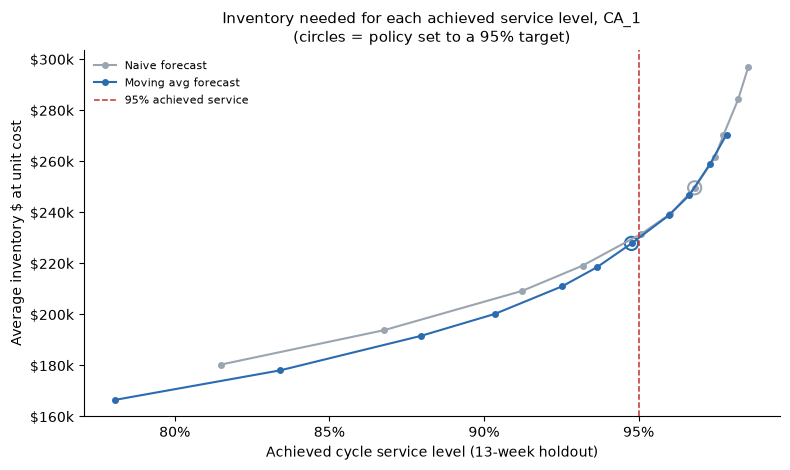

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8))
colors = {"Naive": "#9aa5b1", "Moving avg": "#2b6cb0"}
for m in METHODS:
    c = curve[(curve["method"] == m) & (curve["group"] == "All")].sort_values("CSL")
    ax.plot(c["CSL"], c["Avg inventory $"], marker="o", ms=4, color=colors[m],
            label=f"{m} forecast")
    tgt95 = c[np.isclose(c["target"], CSL_TARGET)].iloc[0]
    ax.scatter(tgt95["CSL"], tgt95["Avg inventory $"], s=90, facecolors="none",
               edgecolors=colors[m], linewidths=1.5)
ax.axvline(CSL_TARGET, color="#c53030", ls="--", lw=1.1, label="95% achieved service")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k"))
ax.set_xlabel("Achieved cycle service level (13-week holdout)")
ax.set_ylabel("Average inventory $ at unit cost")
ax.set_title("Inventory needed for each achieved service level, CA_1\n"
             "(circles = policy set to a 95% target)", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / f"service_vs_inventory_naive_vs_ma_{STORE_ID}.png", dpi=150)
plt.show()

## 4. Why the realized saving is smaller than planned

The formula sizes safety stock from forecast **error** only. It ignores how much the forecast itself **moves** from week to week.
- The naive forecast is last week's sales, so it jumps as much as demand does. After a high week the reorder point jumps up and the store orders. After a low week it drops back, but stock already ordered cannot be sent back.
- So a jumpy forecast leaves extra stock on the shelf that the safety stock formula never counted. That hidden buffer is what pushed the naive policy above its 95% target.

Check, at the 95% target with weekly-updated forecasts:
- **Forecast swing:** standard deviation of each SKU's weekly forecast over the 13 weeks, summed over SKUs (compared with the same measure for actual demand)
- **Planned avg inventory** $= (SS + Q/2 + \bar{d}R/2) \times C$, the workbook formula ($Q$ rounded up to whole units, as in the simulation)
- **Simulated avg inventory:** what the policy actually held in the replay

In [6]:
swing = {}
for m in METHODS:
    ss = z * sigma[m] * np.sqrt(PROTECT)
    planned = ((ss + Q_units / 2 + d * REVIEW / 2) * C)[active].sum()
    simulated = replay(m, CSL_TARGET)["inv_$"].sum()
    swing[m] = {"Forecast swing (sum of SD, units)": forecast[m][active].std(axis=1).sum(),
                "Planned avg inventory $": planned,
                "Simulated avg inventory $": simulated,
                "Extra stock vs plan $": simulated - planned,
                "Extra stock vs plan %": simulated / planned - 1}
swing = pd.DataFrame(swing).T
print(f"Actual demand swing (sum of SD, units): {demand[active].std(axis=1).sum():,.0f}")
swing.style.format({"Forecast swing (sum of SD, units)": "{:,.0f}", "Planned avg inventory $": "${:,.0f}",
                    "Simulated avg inventory $": "${:,.0f}", "Extra stock vs plan $": "${:,.0f}",
                    "Extra stock vs plan %": "{:+.1%}"})

Actual demand swing (sum of SD, units): 11,768


,"Forecast swing (sum of SD, units)",Planned avg inventory $,Simulated avg inventory $,Extra stock vs plan $,Extra stock vs plan %
Naive,"11,655","$237,356","$249,587","$12,231",+5.2%
Moving avg,"6,402","$228,971","$227,803","$-1,168",-0.5%


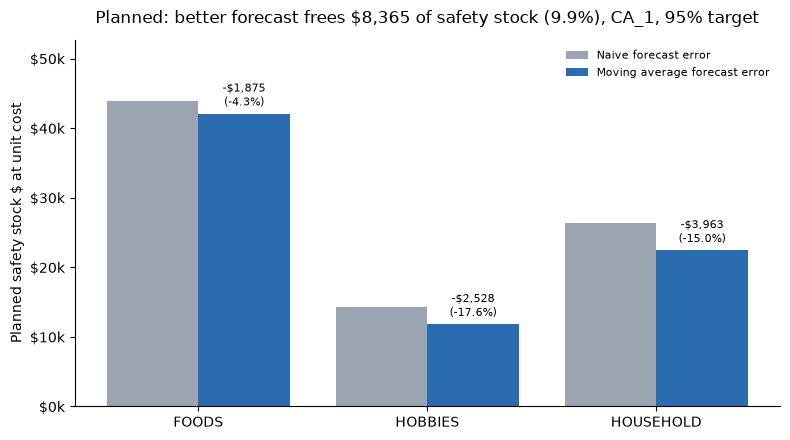

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cats = ["FOODS", "HOBBIES", "HOUSEHOLD"]
x = np.arange(len(cats))
nv = planned_cat.loc[cats, "SS $ Naive"].to_numpy()
ma = planned_cat.loc[cats, "SS $ Moving avg"].to_numpy()
ax.bar(x - 0.2, nv, 0.4, label="Naive forecast error", color="#9aa5b1")
ax.bar(x + 0.2, ma, 0.4, label="Moving average forecast error", color="#2b6cb0")
for xi, a, b in zip(x, nv, ma):
    ax.text(xi + 0.2, b + nv.max() * 0.015, f"-${a - b:,.0f}\n({(b - a) / a:+.1%})",
            ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, cats)
ax.set_ylim(0, nv.max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k"))
ax.set_ylabel("Planned safety stock $ at unit cost")
tot = planned_cat.loc["Total"]
ax.set_title(f"Planned: better forecast frees ${tot['Freed up $']:,.0f} of safety stock "
             f"({tot['Freed up %']:.1%}), CA_1, 95% target", pad=12)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / f"ss_dollars_naive_vs_ma_{STORE_ID}.png", dpi=150)
plt.show()

## Reading the results


**1. On paper, the better forecast frees $8,365 of safety stock (9.9%).**
- Naive $84,646 vs moving average $76,281 at a 95% target, about $2,091 per year in holding cost.
- HOBBIES -17.6% and HOUSEHOLD -15.0% drive most of it. FOODS only -4.3%.
- Regular SKUs save 10.9%. Slow movers need 3.1% more with the moving average.

**2. Updating the forecast every week closes most of the Step 4 service gap.**
- With the forecast fixed at the training average (Step 4), the moving average policy reached 88.5% CSL.
- With the forecast updated weekly, as a store would run it: 94.8% CSL and 99.0% fill rate, essentially on the 95% target.
- So most of the remaining Step 4 gap came from the stale forecast, not the safety stock formula.

**3. At the same 95% target, the two forecasts deliver different service.**
- Naive: 96.8% CSL with $249,587 average inventory. Moving average: 94.8% with $227,803.
- The naive policy holds $21,784 more stock, but part of that buys extra service. A fair comparison has to hold service constant.

**4. At equal achieved service, the realized saving is much smaller than planned.**
- At 95% achieved CSL: $1,076 less average inventory with the moving average (0.5%), not $8,365.
- It is larger at lower service levels: $6,033 (2.9%) at 90% and $6,510 (3.4%) at 85%. At 97% the two are about equal.
- By group at 95%: HOUSEHOLD saves 4.2%, regular SKUs 2.0%, HOBBIES 1.8%. FOODS needs 1.5% more with the moving average.

**5. Why: the naive forecast hides extra buffer.**
- Naive forecasts swing almost as much as demand (11,655 vs 11,768 units, summed SD). The moving average swings 45% less (6,402).
- Every jump up in the naive forecast triggers orders that cannot be undone, so the naive policy held $12,231 (5.2%) more stock than its plan. The moving average held almost exactly its plan (-0.5%).
- The safety stock formula only sees forecast error, so it credits the better forecast with savings that a jumpy forecast partly recovers through extra stock.

**6. What a planner should take from this.**
- A forecast accuracy gain is a real input to inventory, but the planned dollar saving is an upper bound. Validate it on held-out demand at equal service before booking it.
- Limits: one store, 13 weeks, sales used as demand, and assumed costs and lead time. Treat the realized figures as directional.